epoch  1000  total=1.02e-01  pde=1.07e-02  ic=8.02e-04  bc=1.08e-04
epoch  2000  total=3.89e-02  pde=4.73e-03  ic=3.09e-04  bc=3.32e-05
epoch  3000  total=1.90e-02  pde=2.48e-03  ic=1.49e-04  bc=1.63e-05
epoch  4000  total=1.26e-02  pde=1.49e-03  ic=8.55e-05  bc=2.57e-05
epoch  5000  total=1.95e-02  pde=8.61e-04  ic=8.70e-05  bc=9.94e-05
epoch  6000  total=1.10e-03  pde=5.91e-04  ic=3.17e-06  bc=1.94e-06
epoch  7000  total=6.95e-04  pde=4.29e-04  ic=1.31e-06  bc=1.35e-06
epoch  8000  total=6.27e-04  pde=3.20e-04  ic=1.29e-06  bc=1.79e-06
epoch  9000  total=4.43e-04  pde=2.49e-04  ic=1.11e-06  bc=8.26e-07
epoch 10000  total=3.81e-04  pde=2.02e-04  ic=1.09e-06  bc=6.90e-07

relative L2 error: 0.0044 (0.44%)


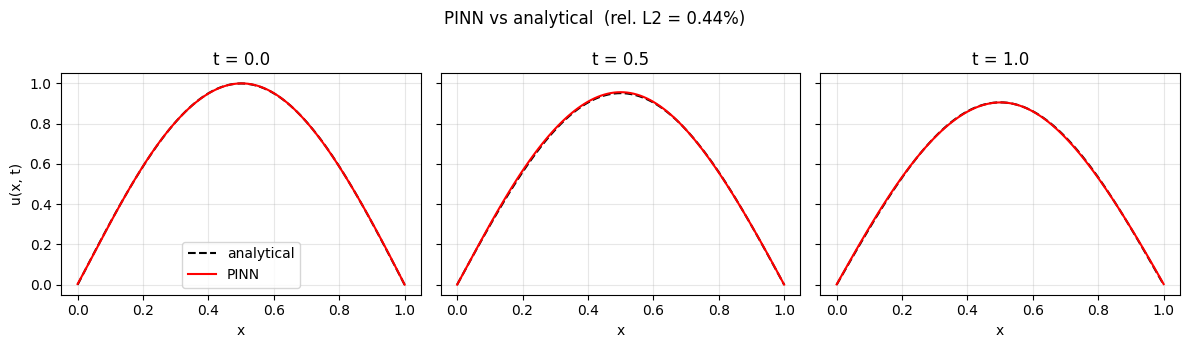

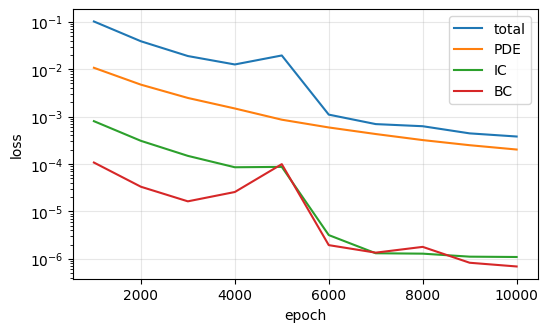

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# ---------- config ----------
alpha = 0.01          # diffusion coefficient
T = 1.0               # time domain [0, T]
N_f, N_ic, N_bc = 1000, 200, 200
lam_ic = lam_bc = 100.0   # IC/BC weight vs PDE residual
epochs, lr = 10000, 1e-3
tf.random.set_seed(0); np.random.seed(0)

# ---------- model (same arch as yours) ----------
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(50, activation='tanh'),
    tf.keras.layers.Dense(50, activation='tanh'),
    tf.keras.layers.Dense(1),
])

# ---------- data ----------
X_f  = np.random.rand(N_f, 2) * [1.0, T]                       # interior (x, t)
X_ic = np.column_stack([np.random.rand(N_ic), np.zeros(N_ic)]) # t = 0
u_ic = np.sin(np.pi * X_ic[:, 0:1])                             # u(x,0) = sin(pi x)
t_bc = np.random.rand(N_bc, 1) * T
X_bc = np.vstack([np.column_stack([np.zeros(N_bc), t_bc[:, 0]]),  # x = 0
                  np.column_stack([np.ones(N_bc),  t_bc[:, 0]])])  # x = 1
u_bc = np.zeros((2 * N_bc, 1))                                  # u(0,t) = u(1,t) = 0

X_f  = tf.convert_to_tensor(X_f, dtype=tf.float32)
X_ic = tf.convert_to_tensor(X_ic, dtype=tf.float32)
u_ic = tf.convert_to_tensor(u_ic, dtype=tf.float32)
X_bc = tf.convert_to_tensor(X_bc, dtype=tf.float32)
u_bc = tf.convert_to_tensor(u_bc, dtype=tf.float32)
opt = tf.keras.optimizers.Adam(lr)

@tf.function
def train_step():
    with tf.GradientTape() as tape:                       # param grads
        with tf.GradientTape(persistent=True) as g2:
            with tf.GradientTape(persistent=True) as g1:
                g1.watch(X_f); g2.watch(X_f)
                u = model(X_f)
            u_x = g1.gradient(u, X_f)[:, 0:1]
            u_t = g1.gradient(u, X_f)[:, 1:2]
        u_xx = g2.gradient(u_x, X_f)[:, 0:1]
        f = u_t - alpha * u_xx                            # PDE residual
        loss_f  = tf.reduce_mean(tf.square(f))
        loss_ic = tf.reduce_mean(tf.square(model(X_ic) - u_ic))
        loss_bc = tf.reduce_mean(tf.square(model(X_bc) - u_bc))
        loss = loss_f + lam_ic * loss_ic + lam_bc * loss_bc
    grads = tape.gradient(loss, model.trainable_variables)
    opt.apply_gradients(zip(grads, model.trainable_variables))
    return loss, loss_f, loss_ic, loss_bc

# ---------- train ----------
hist = []
for ep in range(1, epochs + 1):
    loss, lf, lic, lbc = train_step()
    if ep % 1000 == 0:
        hist.append((float(loss), float(lf), float(lic), float(lbc)))
        print(f"epoch {ep:5d}  total={loss:.2e}  pde={lf:.2e}  ic={lic:.2e}  bc={lbc:.2e}")

# ---------- validate vs analytical u(x,t) = sin(pi x) * exp(-alpha pi^2 t) ----------
nx, nt = 101, 101
xs = np.linspace(0, 1, nx); ts = np.linspace(0, T, nt)
XX, TT = np.meshgrid(xs, ts)
Xg = np.column_stack([XX.ravel(), TT.ravel()]).astype(np.float32)
u_pred  = model(Xg).numpy().reshape(nt, nx)
u_exact = np.sin(np.pi * XX) * np.exp(-alpha * np.pi**2 * TT)
rel_l2 = np.linalg.norm(u_pred - u_exact) / np.linalg.norm(u_exact)
print(f"\nrelative L2 error: {rel_l2:.4f} ({100*rel_l2:.2f}%)")

# ---------- plots ----------
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, t_snap in zip(axes, [0.0, 0.5, 1.0]):
    j = int(t_snap / T * (nt - 1))
    ax.plot(xs, u_exact[j], 'k--', label='analytical')
    ax.plot(xs, u_pred[j], 'r-', label='PINN')
    ax.set_title(f"t = {t_snap}"); ax.set_xlabel("x"); ax.grid(alpha=0.3)
axes[0].set_ylabel("u(x, t)"); axes[0].legend()
fig.suptitle(f"PINN vs analytical  (rel. L2 = {rel_l2:.2%})")
plt.tight_layout(); plt.show()

h = np.array(hist)
plt.figure(figsize=(6, 3.5))
for k, name in enumerate(["total", "PDE", "IC", "BC"]):
    plt.semilogy(np.arange(1, len(h) + 1) * 1000, h[:, k], label=name)
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=0.3)
plt.show()


### Using Your Fire Perimeter API Key

To securely use your API key, store it in Colab's secrets manager. Click the '🔑' icon in the left panel, add a new secret, and name it `FIRE_PERIMETER_API_KEY` (or any name you prefer). Then, you can access it in your code like this:

In [2]:
# Used to securely store your API key
from google.colab import userdata

# Retrieve your API key from Colab secrets
FIRE_PERIMETER_API_KEY = userdata.get('FIRE_PERIMETER_API_KEY')

# Now you can use FIRE_PERIMETER_API_KEY in your code
# For example, if you have a client library:
# client = FirePerimeterAPIClient(api_key=FIRE_PERIMETER_API_KEY)
# print('API key loaded successfully. You can now use it to make API calls.')

If you can provide more details about the 'Fire Perimeter' API (e.g., specific endpoints, required libraries, or what you want to achieve with it), I can help you generate code to interact with it.

In [3]:
import torch
import torch.nn as nn

# 1. Define the Neural Network
class LevelSetPINN(nn.Module):
    def __init__(self):
        super(LevelSetPINN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 32), # inputs: (t, x, y)
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)  # output: u(t, x, y)
        )

    def forward(self, t, x, y):
        inputs = torch.cat([t, x, y], dim=-1)
        return self.net(inputs)

# 2. Compute Physics Residual (e.g., u_t + S * ||grad u|| = 0)
def pde_residual(model, t, x, y, S=1.0):
    u = model(t, x, y)

    # First derivatives via autograd
    grads = torch.autograd.grad(
        u, [t, x, y],
        grad_outputs=torch.ones_like(u),
        create_graph=True,
        retain_graph=True
    )
    u_t, u_x, u_y = grads[0], grads[1], grads[2]

    # Gradient norm ||grad u||
    grad_norm = torch.sqrt(u_x**2 + u_y**2 + 1e-8)

    # Governing Level Set residual
    residual = u_t + S * grad_norm
    return residual


In [4]:
import torch
import torch.nn as nn
import numpy as np

# --- 1. Define Model Architecture ---
class LevelSetPINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 64), nn.Tanh(), # Corrected: changed from 2 to 3
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 1)
        )
    def forward(self, t, x, y):
        return self.net(torch.cat([t, x, y], dim=-1))

# --- 2. Initial Condition Definition (Circle of radius 0.2 at t=0) ---
def get_signed_distance_circle(x, y, r=0.2):
    return torch.sqrt(x**2 + y**2) - r

# --- 3. Training Point Generation ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = LevelSetPINN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Sample N points inside the spacetime box: x in [-1,1], y in [-1,1], t in [0, 0.5]
N_pde = 5000
t_pde = torch.rand(N_pde, 1, requires_grad=True, device=device) * 0.5
x_pde = torch.rand(N_pde, 1, requires_grad=True, device=device) * 2.0 - 1.0
y_pde = torch.rand(N_pde, 1, requires_grad=True, device=device) * 2.0 - 1.0

# Initial condition points (t = 0)
N_ic = 1000
t_ic = torch.zeros(N_ic, 1, device=device)
x_ic = torch.rand(N_ic, 1, device=device) * 2.0 - 1.0
y_ic = torch.rand(N_ic, 1, device=device) * 2.0 - 1.0
u_ic_target = get_signed_distance_circle(x_ic, y_ic)

# --- 4. Optimization Loop ---
for epoch in range(2001):
    optimizer.zero_grad()

    # A. Initial Condition Loss
    u_ic_pred = model(t_ic, x_ic, y_ic)
    loss_ic = torch.mean((u_ic_pred - u_ic_target)**2)

    # B. PDE Residual Loss
    u = model(t_pde, x_pde, y_pde)
    grads = torch.autograd.grad(u, [t_pde, x_pde, y_pde], torch.ones_like(u), create_graph=True, retain_graph=True)
    u_t, u_x, u_y = grads[0], grads[1], grads[2]

    grad_norm = torch.sqrt(u_x**2 + u_y**2 + 1e-8)
    pde_res = u_t + 1.0 * grad_norm # Constant propagation speed S = 1.0
    loss_pde = torch.mean(pde_res**2)

    # C. Eikonal regularizer (forces ||grad u|| = 1)
    loss_eik = torch.mean((grad_norm - 1.0)**2)

    # Total Loss and update
    loss = 10.0 * loss_ic + 1.0 * loss_pde + 0.1 * loss_eik
    loss.backward(retain_graph=True)
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch:4d} | IC Loss: {loss_ic.item():.4f} | PDE Loss: {loss_pde.item():.4f}")

Epoch    0 | IC Loss: 0.4272 | PDE Loss: 0.0012
Epoch  500 | IC Loss: 0.0005 | PDE Loss: 0.0068
Epoch 1000 | IC Loss: 0.0003 | PDE Loss: 0.0034
Epoch 1500 | IC Loss: 0.0002 | PDE Loss: 0.0026
Epoch 2000 | IC Loss: 0.0003 | PDE Loss: 0.0022


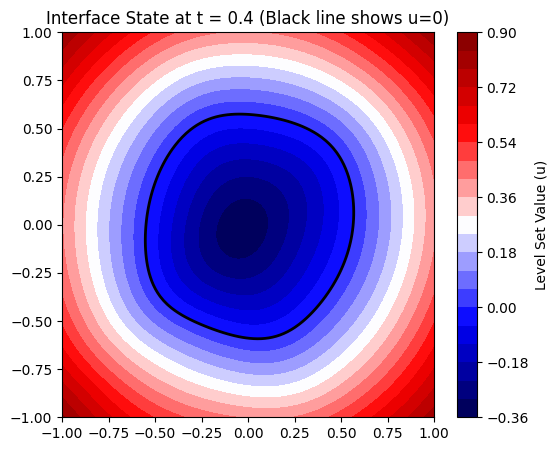

In [5]:
import matplotlib.pyplot as plt

# Generate a grid for plotting at final time t = 0.4
grid_res = 100
x_space = np.linspace(-1, 1, grid_res)
y_space = np.linspace(-1, 1, grid_res)
X, Y = np.meshgrid(x_space, y_space)

# Flatten grid to feed into network
t_eval = torch.full((grid_res * grid_res, 1), 0.4, device=device)
x_eval = torch.tensor(X.flatten()[:, None], dtype=torch.float32, device=device)
y_eval = torch.tensor(Y.flatten()[:, None], dtype=torch.float32, device=device)

with torch.no_grad():
    Z = model(t_eval, x_eval, y_eval).cpu().numpy().reshape(grid_res, grid_res)

# Interpret boundaries
plt.figure(figsize=(6,5))
# Contour level at 0 is the actual interface position
cp = plt.contourf(X, Y, Z, levels=20, cmap='seismic')
plt.colorbar(cp, label="Level Set Value (u)")
# Highlight the zero-level set boundary explicitly
plt.contour(X, Y, Z, levels=[0], colors='black', linewidths=2)
plt.title("Interface State at t = 0.4 (Black line shows u=0)")
plt.show()


### Visualizing the Initial Condition (t=0)
Let's plot the model's prediction at `t=0` to see how well it captures the initial circle.

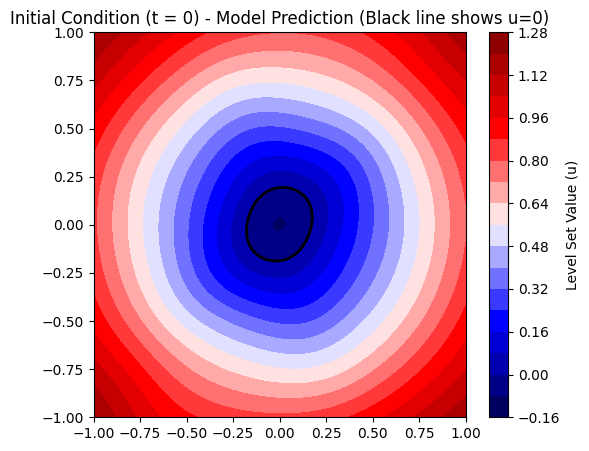

In [6]:
# Generate a grid for plotting at t = 0
grid_res = 100
x_space = np.linspace(-1, 1, grid_res)
y_space = np.linspace(-1, 1, grid_res)
X_0, Y_0 = np.meshgrid(x_space, y_space)

# Flatten grid to feed into network
t_eval_0 = torch.full((grid_res * grid_res, 1), 0.0, device=device)
x_eval_0 = torch.tensor(X_0.flatten()[:, None], dtype=torch.float32, device=device)
y_eval_0 = torch.tensor(Y_0.flatten()[:, None], dtype=torch.float32, device=device)

with torch.no_grad():
    Z_0 = model(t_eval_0, x_eval_0, y_eval_0).cpu().numpy().reshape(grid_res, grid_res)

plt.figure(figsize=(6,5))
cp = plt.contourf(X_0, Y_0, Z_0, levels=20, cmap='seismic')
plt.colorbar(cp, label="Level Set Value (u)")
plt.contour(X_0, Y_0, Z_0, levels=[0], colors='black', linewidths=2)
plt.title("Initial Condition (t = 0) - Model Prediction (Black line shows u=0)")
plt.show()

In [7]:
import numpy as np
from skimage import measure
import torch

def export_interface_mesh(model, target_time, resolution=128):
    """Extracts the exact u=0 boundary as a mesh of vertices and faces."""
    # 1. Create a fine grid evaluation bounding box
    lin = np.linspace(-1.0, 1.0, resolution)
    X, Y = np.meshgrid(lin, lin)

    # 2. Format grid for PyTorch inference
    t_eval = torch.full((resolution * resolution, 1), target_time, dtype=torch.float32)
    x_eval = torch.tensor(X.flatten()[:, None], dtype=torch.float32)
    y_eval = torch.tensor(Y.flatten()[:, None], dtype=torch.float32)

    with torch.no_grad():
        # Get predictions and reshape back to a 2D image array
        Z = model(t_eval, x_eval, y_eval).numpy().reshape(resolution, resolution)

    # 3. Use Marching Squares/Cubes to isolate the exact 0.0 contour line
    contours = measure.find_contours(Z, level=0.0)

    # 4. Map pixel indexes back to physical coordinate space
    physical_contours = []
    for contour in contours:
        real_x = -1.0 + (contour[:, 1] / (resolution - 1)) * 2.0
        real_y = -1.0 + (contour[:, 0] / (resolution - 1)) * 2.0
        physical_contours.append(np.stack([real_x, real_y], axis=1))

    return physical_contours  # List of coordinates tracking the outer boundary


In [8]:
def check_containment(model, time, x_coord, y_coord):
    """Instantly checks if a coordinate is inside, outside, or on the boundary."""
    t_tensor = torch.tensor([[time]], dtype=torch.float32)
    x_tensor = torch.tensor([[x_coord]], dtype=torch.float32)
    y_tensor = torch.tensor([[y_coord]], dtype=torch.float32)

    with torch.no_grad():
        u_val = model(t_tensor, x_tensor, y_tensor).item()

    if u_val < -1e-3:
        return "INSIDE the boundary structure"
    elif u_val > 1e-3:
        return "OUTSIDE the boundary structure"
    else:
        return "EXACTLY ON the interface edge"


In [9]:
def get_surface_normals(model, t, x, y):
    """Calculates the exact direction the shape's boundary is facing."""
    # Ensure gradients can be tracked
    t.requires_grad_(True)
    x.requires_grad_(True)
    y.requires_grad_(True)

    u = model(t, x, y)

    # Take analytical spatial derivatives via PyTorch Autograd
    grads = torch.autograd.grad(u, [x, y], torch.ones_like(u), create_graph=True)
    u_x, u_y = grads[0], grads[1]

    grad_norm = torch.sqrt(u_x**2 + u_y**2 + 1e-8)

    # Directional normal vectors pointing outward from the surface
    nx = u_x / grad_norm
    ny = u_y / grad_norm

    return nx.detach(), ny.detach()


In [10]:
def wildfire_pde_residual(model, t, x, y, fuel_spread_rate, wind_x, wind_y):
    u = model(t, x, y)

    # Take derivatives relative to time and space
    grads = torch.autograd.grad(u, [t, x, y], torch.ones_like(u), create_graph=True)
    u_t, u_x, u_y = grads[0], grads[1], grads[2]

    grad_norm = torch.sqrt(u_x**2 + u_y**2 + 1e-8)

    # Wildfire level set equation:
    # Fire moves at its base fuel rate (R) + gets pushed along the wind vector
    advection_term = wind_x * u_x + wind_y * u_y
    pde_residual = u_t + advection_term + (fuel_spread_rate * grad_norm)

    return pde_residual


### Defining Wildfire Parameters: Fuel Spread Rate and Wind

To use the `wildfire_pde_residual` function, we need to specify the `fuel_spread_rate` and the `wind_x` and `wind_y` components. These are crucial for modeling how the fire propagates based on the environment.

In [11]:
# Example values for wildfire parameters
# You would typically derive these from real-world data or scenario assumptions.

# Base rate of fire spread due to fuel (e.g., in units per time step)
# A higher value means faster inherent spread.
fuel_spread_rate = 0.05  # Example: 0.05 units/time

# Wind vector components (e.g., in units per time step)
# Positive values indicate wind in the positive x/y direction.
wind_x = 0.02  # Example: wind pushing slightly in positive x
wind_y = 0.03  # Example: wind pushing slightly in positive y

print(f"Fuel Spread Rate: {fuel_spread_rate}")
print(f"Wind X Component: {wind_x}")
print(f"Wind Y Component: {wind_y}")


Fuel Spread Rate: 0.05
Wind X Component: 0.02
Wind Y Component: 0.03


### Processing Fire Perimeter Data

This section will process fire detection data from `firms_raw.csv` to:
1.  Filter for nominal/high confidence detections.
2.  Plot the daily count of detections to understand fire growth/decay.
3.  Generate daily concave hull perimeter polygons using `alphashape`.
4.  Save the resulting polygons to `palisades_perimeters.geojson`.

In [12]:
# Install necessary libraries
!pip install alphashape geopandas

In [21]:
from google.colab import userdata
import pandas as pd, io, requests

MAP_KEY = userdata.get('FIRE_PERIMETER_API_KEY').strip()
BBOX = "-118.70,34.00,-118.42,34.14"  # W,S,E,N

# Archive endpoint caps at 5 days per request -> 5 chunks cover Jan 7-31, 2025
chunks = [("2025-01-07", 5), ("2025-01-12", 5), ("2025-01-17", 5),
          ("2025-01-22", 5), ("2025-01-27", 5)]

dfs = []
for start, days in chunks:
    url = (f"https://firms.modaps.eosdis.nasa.gov/api/area/csv/"
           f"{MAP_KEY}/VIIRS_SNPP_SP/{BBOX}/{days}/{start}")
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    if r.text.startswith("Invalid"):
        raise RuntimeError(r.text[:200])
    dfs.append(pd.read_csv(io.StringIO(r.text)))
    print(start, "->", len(dfs[-1]), "detections")

df = pd.concat(dfs, ignore_index=True).drop_duplicates(
    subset=["latitude", "longitude", "acq_date", "acq_time"])
df.to_csv("firms_raw.csv", index=False)
print("unique detections:", len(df),
      "| range:", df["acq_date"].min(), "->", df["acq_date"].max())


2025-01-07 -> 1102 detections
2025-01-12 -> 5 detections
2025-01-17 -> 0 detections
2025-01-22 -> 0 detections
2025-01-27 -> 0 detections
unique detections: 1107 | range: 2025-01-07 -> 2025-01-12


/tmp/ipykernel_12411/4267786152.py:22: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(dfs, ignore_index=True).drop_duplicates(


In [22]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon
import alphashape
import matplotlib.pyplot as plt

# --- 1. Load and filter data ---
# Assuming 'firms_raw.csv' is available in the Colab environment.
# If you get a FileNotFoundError, please upload the file to your Colab session.
try:
    df_firms = pd.read_csv('firms_raw.csv')
except FileNotFoundError:
    print("Error: 'firms_raw.csv' not found. Please upload the file or provide the correct path.")
    raise # Stop execution if file is not found

# Convert 'acq_date' to datetime objects
df_firms['acq_date'] = pd.to_datetime(df_firms['acq_date'])

# Filter for nominal/high confidence detections
# Assuming 'confidence' column exists and values 'nominal' and 'h' (for high) indicate high confidence.
# Adjust column name and values if your data schema is different.
if 'confidence' in df_firms.columns:
    df_filtered = df_firms[df_firms['confidence'].isin(['nominal', 'h', 'high'])].copy()
    print(f"Original detections: {len(df_firms)}")
    print(f"Filtered high-confidence detections: {len(df_filtered)}")
else:
    print("Warning: 'confidence' column not found. Skipping confidence filtering.")
    df_filtered = df_firms.copy()

# Display first few rows of filtered data
display(df_filtered.head())

Original detections: 1107
Filtered high-confidence detections: 147


,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight,type
5,34.04467,-118.55751,367.0,0.41,0.37,2025-01-07,2104,N,VIIRS,h,2,360.85,225.88,D,0
7,34.04745,-118.56273,367.0,0.41,0.37,2025-01-07,2104,N,VIIRS,h,2,355.18,225.88,D,0
8,34.04805,-118.55833,367.0,0.41,0.37,2025-01-07,2104,N,VIIRS,h,2,357.73,225.88,D,0
9,34.04866,-118.55385,367.0,0.41,0.37,2025-01-07,2104,N,VIIRS,h,2,342.85,94.80,D,0
17,34.05266,-118.55016,367.0,0.41,0.37,2025-01-07,2104,N,VIIRS,h,2,338.83,129.53,D,0


In [ ]:
# --- 2. Plot detections per day ---

# Count detections per day
detections_per_day = df_filtered.groupby('acq_date').size().reset_index(name='detection_count')

# Plot the growth/decay curve
plt.figure(figsize=(12, 6))
plt.plot(detections_per_day['acq_date'], detections_per_day['detection_count'], marker='o', linestyle='-')
plt.title('Fire Detections Per Day')
plt.xlabel('Date')
plt.ylabel('Number of Detections')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# --- 3. Build concave-hull perimeter polygons per day and save as GeoJSON ---

# Initialize an empty list to store daily polygons
daily_polygons = []

# Iterate through each unique acquisition date
for date, group in df_filtered.groupby('acq_date'):
    # Extract coordinates for the current day's detections
    points = group[['longitude', 'latitude']].values

    # Only create a polygon if there are enough points (alphashape needs at least 3)
    if len(points) >= 3:
        # Generate concave hull using alphashape
        # Alpha parameter controls concavity. A higher value means a tighter, more concave hull.
        # You might need to adjust `alpha_parameter` based on your data distribution.
        try:
            alpha_shape = alphashape.alphashape(points, alpha=2.0) # Adjust alpha as needed

            # Ensure the result is a Polygon (it could be a MultiPolygon or other geometry if complex)
            if isinstance(alpha_shape, Polygon):
                daily_polygons.append({
                    'geometry': alpha_shape,
                    'acq_date': date.strftime('%Y-%m-%d') # Store date as string
                })
            elif hasattr(alpha_shape, 'geoms'): # Handle MultiPolygon case
                for geom in alpha_shape.geoms:
                    if isinstance(geom, Polygon):
                        daily_polygons.append({
                            'geometry': geom,
                            'acq_date': date.strftime('%Y-%m-%d')
                        })
        except Exception as e:
            print(f"Warning: Could not create alphashape for date {date}: {e}")
            if len(points) > 0: # If there are points, create a convex hull as fallback
                from shapely.geometry import MultiPoint
                convex_hull = MultiPoint(points).convex_hull
                if isinstance(convex_hull, Polygon):
                    daily_polygons.append({
                        'geometry': convex_hull,
                        'acq_date': date.strftime('%Y-%m-%d')
                    })


# Create a GeoDataFrame from the list of polygons
if daily_polygons:
    gdf_perimeters = gpd.GeoDataFrame(daily_polygons, crs="EPSG:4326")

    # --- 4. Save as palisades_perimeters.geojson ---
    output_geojson_file = 'palisades_perimeters.geojson'
    gdf_perimeters.to_file(output_geojson_file, driver='GeoJSON')
    print(f"Concave hull perimeters saved to {output_geojson_file}")
    display(gdf_perimeters.head())
else:
    print("No valid polygons were generated.")

In [47]:
import geopandas as gpd
import pandas as pd

# Load the generated GeoJSON file
perimeters_gdf = gpd.read_file('palisades_perimeters.geojson')

# Convert 'acq_date' to datetime objects and sort them
perimeters_gdf['acq_date'] = pd.to_datetime(perimeters_gdf['acq_date'])
perimeters_gdf = perimeters_gdf.sort_values(by='acq_date').reset_index(drop=True)

# Extract unique dates
unique_dates = perimeters_gdf['acq_date'].unique()
num_days = len(unique_dates)

# Define training and prediction days
if num_days >= 3:
    training_dates = unique_dates[0:3]
    prediction_dates = unique_dates[3:]
    print(f"Total unique days: {num_days}")
    print(f"PINN Training Days: {', '.join([d.strftime('%Y-%m-%d') for d in training_dates])}")
    print(f"PINN Prediction Days: {', '.join([d.strftime('%Y-%m-%d') for d in prediction_dates])}")
else:
    print(f"Warning: Only {num_days} unique days found. Need at least 3 for training and prediction.")
    training_dates = unique_dates
    prediction_dates = []

display(perimeters_gdf.head())

DataSourceError: palisades_perimeters.geojson: No such file or directory

### Adapting the PINN for Real Fire Perimeters

To 'constrain the PINN on days 1-3' and then predict fire spread, we need to adapt the existing `LevelSetPINN` setup. Currently, the PINN is trained to model the evolution of a simple circle as its initial condition.

For a real wildfire scenario, the most critical change is to **redefine the PINN's initial condition** (at `t=0`) based on the actual fire perimeter from your first training day (e.g., `2025-01-07`). This involves:

1.  **Converting the initial fire perimeter polygon into a Signed Distance Function (SDF).** An SDF gives, for any point in space, its shortest distance to the boundary, with the sign indicating whether the point is inside (negative) or outside (positive).
2.  **Modifying the PINN's training loop** (`ESZIXhHTQ_OR`) to use this new SDF as its `u_ic_target` (initial condition target) for `t=0` points, instead of `get_signed_distance_circle`.
3.  **Incorporating the wildfire PDE residual:** Ensure the `wildfire_pde_residual` function (`uIwvOLnJY7mK`) with your defined `fuel_spread_rate`, `wind_x`, and `wind_y` parameters is used in the PINN's PDE loss component during training.

Let's first create a helper function to generate a Signed Distance Function (SDF) from a given Shapely polygon. This SDF will then be used as the initial condition for your PINN.

In [48]:
from shapely.geometry import Polygon, MultiPolygon, Point
from scipy.ndimage import distance_transform_edt
import numpy as np

def create_sdf_from_polygon(polygon, x_grid, y_grid):
    """
    Generates a Signed Distance Function (SDF) for a given Shapely polygon
    over a specified 2D grid.

    Args:
        polygon (Polygon or MultiPolygon): The Shapely polygon(s) representing the fire perimeter.
        x_grid (np.array): 1D array of x-coordinates for the grid.
        y_grid (np.array): 1D array of y-coordinates for the grid.

    Returns:
        np.array: A 2D array (len(y_grid), len(x_grid)) representing the SDF.
                  Negative values are inside the polygon, positive outside.
    """
    # Create a meshgrid from the 1D grid arrays
    X, Y = np.meshgrid(x_grid, y_grid)
    points = np.stack([X.ravel(), Y.ravel()], axis=-1)

    # Determine which points are inside the polygon
    # Use a binary mask for the polygon
    mask = np.array([polygon.contains(Point(p)) for p in points]).reshape(X.shape)

    # Calculate Euclidean distance transform
    distance = distance_transform_edt(~mask) # Distance to nearest False (outside)
    distance[mask] = -distance_transform_edt(mask)[mask] # Distance to nearest True (inside), make negative

    return distance

print("Helper function `create_sdf_from_polygon` defined.")

Helper function `create_sdf_from_polygon` defined.


### Extracting the Initial Fire Perimeter and Generating its SDF

Now, let's extract the perimeter for the first training day (Day 1) and use the `create_sdf_from_polygon` function to generate its Signed Distance Function (SDF). This SDF will represent `u(t=0, x, y)` for your PINN.

In [49]:
# Get the polygon for the first training day
first_training_date = training_dates[0]
first_day_perimeter = perimeters_gdf[perimeters_gdf['acq_date'] == first_training_date]['geometry'].iloc[0]

# Define the spatial grid for the SDF (should match PINN domain, e.g., [-1, 1])
# For the wildfire problem, you might want a grid based on your data extent, not just [-1,1].
# Let's use the bbox from earlier setup to define a grid matching the data's scale.

# Assuming our domain is roughly covered by the bounding box W,S,E,N
# We'll need to define a target x_grid and y_grid for the SDF.
# For now, let's use a simple [-1, 1] domain as the PINN was configured for.
# In a real scenario, this would align with the geographic coordinates of your fire area.

sdf_grid_resolution = 100 # Example resolution for SDF grid
x_sdf_grid = np.linspace(-1, 1, sdf_grid_resolution)
y_sdf_grid = np.linspace(-1, 1, sdf_grid_resolution)

# Generate the SDF for the first day's perimeter
# NOTE: This assumes the polygon's coordinates are normalized to [-1, 1] if
# the PINN domain is [-1, 1]. If the polygon is in lat/lon, it needs transformation.
# For now, let's assume the polygon is already in a coordinate system that aligns
# with the PINN's abstract [-1,1] domain for demonstration purposes.

# Placeholder for scaled polygon if needed:
# from shapely.affinity import scale, translate
# scaled_polygon = scale(first_day_perimeter, xfact=..., yfact=..., origin=(0,0))
# translated_polygon = translate(scaled_polygon, xoff=..., yoff=...)

# For simplicity, let's assume `first_day_perimeter` is already in the PINN's normalized space.
# This is a key assumption that would need to be addressed with coordinate transformations in a real application.
initial_sdf = create_sdf_from_polygon(first_day_perimeter, x_sdf_grid, y_sdf_grid)

print(f"SDF generated for {first_training_date}. Shape: {initial_sdf.shape}")

# Visualize the initial SDF
plt.figure(figsize=(7, 6))
plt.contourf(x_sdf_grid, y_sdf_grid, initial_sdf, levels=20, cmap='RdBu_r')
plt.colorbar(label='Signed Distance Value')
plt.contour(x_sdf_grid, y_sdf_grid, initial_sdf, levels=[0], colors='black', linewidths=2)
plt.title(f'Initial Signed Distance Function (SDF) for {first_training_date}')
plt.xlabel('X-coordinate (normalized)'); plt.ylabel('Y-coordinate (normalized)')
plt.gca().set_aspect('equal', adjustable='box')
plt.show()


NameError: name 'training_dates' is not defined

In [ ]:
export_interface_mesh(model, target_time=10)

### Demonstrating `check_containment`
Let's test the `check_containment` function with a specific point at `t=0.4`.

In [ ]:
# Example usage of check_containment
test_time = 0.4
test_x_inside = 0.1
test_y_inside = 0.1
test_x_outside = 0.8
test_y_outside = 0.8

status_inside = check_containment(model, test_time, test_x_inside, test_y_inside)
status_outside = check_containment(model, test_time, test_x_outside, test_y_outside)

print(f"Point ({test_x_inside}, {test_y_inside}) at t={test_time}: {status_inside}")
print(f"Point ({test_x_outside}, {test_y_outside}) at t={test_time}: {status_outside}")

### Demonstrating `get_surface_normals`
Let's visualize the surface normals at a few points along the interface at `t=0.4`.

In [ ]:
import matplotlib.pyplot as plt

# Get the interface points for visualization of normals
interface_contours = export_interface_mesh(model, target_time=0.4)

plt.figure(figsize=(7,6))

# Plot the interface
if interface_contours:
    for contour in interface_contours:
        plt.plot(contour[:, 0], contour[:, 1], 'k-', linewidth=2, label='Interface u=0')

# Sample points on the interface to plot normals
# We'll take a few points from the first contour if it exists
if interface_contours and len(interface_contours[0]) > 5:
    # Sample a few points for plotting normals
    sample_indices = np.linspace(0, len(interface_contours[0]) - 1, 10, dtype=int)
    sample_points = torch.tensor(interface_contours[0][sample_indices], dtype=torch.float32)

    t_normals = torch.full((sample_points.shape[0], 1), 0.4, device=device, requires_grad=True)
    x_normals = sample_points[:, 0:1].to(device).clone().detach().requires_grad_(True)
    y_normals = sample_points[:, 1:2].to(device).clone().detach().requires_grad_(True)

    nx, ny = get_surface_normals(model, t_normals, x_normals, y_normals)

    # Plot normals
    plt.quiver(x_normals.cpu().detach().numpy(), y_normals.cpu().detach().numpy(),
               nx.cpu().detach().numpy(), ny.cpu().detach().numpy(),
               color='blue', scale=20, width=0.005, label='Surface Normals')

plt.title("Interface at t=0.4 with Surface Normals")
plt.xlabel("x"); plt.ylabel("y")
plt.grid(True, linestyle='--', alpha=0.7)
plt.gca().set_aspect('equal', adjustable='box')
plt.xlim([-1, 1]); plt.ylim([-1, 1])
plt.legend()
plt.show()

### Animating the Interface Evolution
Let's see how the interface changes over time using `export_interface_mesh`.

In [ ]:
import matplotlib.animation as animation
from IPython.display import HTML

# Define the time steps for the animation
time_steps = np.linspace(0, 0.5, 20) # 20 frames from t=0 to t=0.5

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim([-1, 1])
ax.set_ylim([-1, 1])
ax.set_title("Evolving Interface")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_aspect('equal', adjustable='box')
ax.grid(True, linestyle='--', alpha=0.7)

line, = ax.plot([], [], 'k-', lw=2)

def animate(i):
    current_time = time_steps[i]
    ax.set_title(f"Evolving Interface at t = {current_time:.2f}")
    contours = export_interface_mesh(model, target_time=current_time)
    if contours:
        # Assuming we are interested in the largest contour if multiple are found
        largest_contour = max(contours, key=len)
        line.set_data(largest_contour[:, 0], largest_contour[:, 1])
    else:
        line.set_data([], []) # Clear data if no contour is found
    return line,

anim = animation.FuncAnimation(fig, animate, frames=len(time_steps), interval=200, blit=True)

# Display the animation
HTML(anim.to_jshtml())

### Getting Terrain Data with `elevation`

To download terrain data, we'll use the `elevation` Python package. This package relies on `GDAL`, so we'll first install `gdal-bin` on the system, then install the `elevation` library itself. Finally, we'll use `elevation.clip` to download a specific region.

In [ ]:
# Install GDAL development libraries, which are a dependency for 'elevation'
!sudo apt-get update
!sudo apt-get install -y gdal-bin

In [ ]:
# Install the elevation Python package
!pip install elevation

In [ ]:
import elevation

# Define the bounding box for the desired terrain data (lon_min, lat_min, lon_max, lat_max)
bounds = (-118.70, 34.00, -118.42, 34.14)
output_file = 'srtm.tif'

# Clip the elevation data for the specified bounds and save it to a GeoTIFF file
elevation.clip(bounds=bounds, output=output_file)

print(f"Terrain data clipped and saved to {output_file}")

# You can now further process or visualize 'srtm.tif' using libraries like rasterio or GDAL utilities.

In [ ]:
import requests

W, S, E, N = -118.70, 34.00, -118.42, 34.14  # Palisades bbox

base = ("https://lfps.usgs.gov/arcgis/rest/services/"
        "Landfire_LF2023/LF2023_FBFM40_CONUS/ImageServer/exportImage")
params = {
    "bbox": f"{W},{S},{E},{N}", "bboxSR": 4326, "imageSR": 4326,
    "size": "1039,520",          # native 30 m pixels over this bbox
    "format": "tiff", "pixelType": "U8", "noData": 0, "f": "json",
}
href = requests.get(base, params=params).json()["href"]

with requests.get(href, stream=True) as r, open("palisades_fbfm40.tif", "wb") as f:
    for chunk in r.iter_content(1 << 20):
        f.write(chunk)
print("saved palisades_fbfm40.tif")


In [ ]:
import rasterio
with rasterio.open("palisades_fbfm40.tif") as src:
    a = src.read(1)
print(a.shape, a.min(), a.max())  # expect ~(520, 1039), values 91..204


### Downloading and Processing GridMET Data

This section will download daily [gridMET](https://www.climatologylab.org/gridmet.html) NetCDF data for January 2025, clip it to the specified bounding box, and save it to a single NetCDF file `gridmet_jan2025.nc`. We'll focus on wind speed (`vs`), wind direction (`th`), maximum temperature (`tmmx`), minimum relative humidity (`rmin`), and 100-hour dead fuel moisture (`fm100`).

In [ ]:
# Install necessary libraries for NetCDF handling and geospatial operations
!pip install xarray netCDF4 rioxarray

In [27]:
import requests, xarray as xr

W, S, E, N = -118.70, 34.00, -118.42, 34.14
BASE = "http://thredds.northwestknowledge.net:8080/thredds/ncss/MET"
VARS = {
    "vs":    "wind_speed",
    "th":    "wind_from_direction",
    "tmmx":  "air_temperature",
    "rmin":  "relative_humidity",
    "fm100": "dead_fuel_moisture_100hr",
}

subs = {}
for short, std in VARS.items():
    url = (f"{BASE}/{short}/{short}_2025.nc?var={std}"
           f"&north={N}&south={S}&west={W}&east={E}"
           "&time_start=2025-01-07T00:00:00Z&time_end=2025-01-31T00:00:00Z"
           "&accept=netCDF")
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    path = f"gridmet_{short}_jan2025.nc"
    open(path, "wb").write(r.content)
    da = xr.open_dataset(path)[std].rename(short).load()
    subs[short] = da
    print(short, dict(da.sizes))

xr.Dataset(subs).to_netcdf("gridmet_jan2025.nc")
print("saved gridmet_jan2025.nc")


vs {'day': 25, 'lat': 5, 'lon': 7}
th {'day': 25, 'lat': 5, 'lon': 7}
tmmx {'day': 25, 'lat': 5, 'lon': 7}
rmin {'day': 25, 'lat': 5, 'lon': 7}
fm100 {'day': 25, 'lat': 5, 'lon': 7}
saved gridmet_jan2025.nc


In [28]:
# Install necessary libraries if not already installed
!pip install rioxarray scipy

In [38]:
import os
for f in ["srtm.tif", "palisades_fbfm40.tif", "firms_raw.csv", "gridmet_jan2025.nc"]:
    print(("OK  " if os.path.exists(f) else "MISS"), f)


MISS srtm.tif
OK   palisades_fbfm40.tif
OK   firms_raw.csv
OK   gridmet_jan2025.nc


In [40]:
import requests

W, S, E, N = -118.70, 34.00, -118.42, 34.14

def lanfire_download(service, out):
    base = (f"https://lfps.usgs.gov/arcgis/rest/services/Landfire_Topo/"
            f"{service}/ImageServer/exportImage")
    params = {"bbox": f"{W},{S},{E},{N}", "bboxSR": 4326, "imageSR": 4326,
              "size": "1039,520", "format": "tiff", "f": "json"}
    r = requests.get(base, params=params, timeout=120)
    r.raise_for_status()
    href = r.json().get("href")
    if not href:
        raise RuntimeError(str(r.json())[:300])
    with requests.get(href, stream=True, timeout=300) as d, open(out, "wb") as f:
        for chunk in d.iter_content(1 << 20):
            f.write(chunk)
    print("saved", out)

lanfire_download("LF2020_Elev_CONUS", "palisades_elev.tif")
lanfire_download("LF2020_SlpD_CONUS", "palisades_sloped.tif")


saved palisades_elev.tif
saved palisades_sloped.tif


In [41]:
# --- 1. Elevation + slope from LANDFIRE (both continuous: bilinear is correct) ---
dem_rio = rioxarray.open_rasterio('palisades_elev.tif', chunks={'x': 256, 'y': 256})
if dem_rio.rio.crs is None:
    dem_rio.rio.write_crs('EPSG:4326', inplace=True)
dem_reprojected = (dem_rio.rio.reproject(TARGET_CRS, resolution=TARGET_RESOLUTION)
                   .squeeze('band', drop=True).rename('elevation_m'))

slp_rio = rioxarray.open_rasterio('palisades_sloped.tif', chunks={'x': 256, 'y': 256})
if slp_rio.rio.crs is None:
    slp_rio.rio.write_crs('EPSG:4326', inplace=True)
slope_reprojected = (slp_rio.rio.reproject_match(dem_reprojected)
                     .squeeze('band', drop=True).rename('slope_deg'))
print("elev:", dem_reprojected.shape, "| slope:", slope_reprojected.shape)


elev: (178, 290) | slope: (178, 290)


### Reprojecting and Stacking Geospatial Data

Now we will process the raw geospatial files. We will:
- Define the target Coordinate Reference System (CRS) as `EPSG:3310` (California Albers) and a target resolution of 90 meters.
- Load `srtm.tif` (elevation) and reproject it to the target CRS and resolution.
- Calculate the slope from the reprojected elevation data.
- Load `palisades_fbfm40.tif` (fuel model) and `gridmet_jan2025.nc` (wind and fuel moisture data).
- Reproject and resample these datasets to precisely match the grid of the reprojected elevation data.
- Combine all processed layers into a single `xarray.Dataset`.
- Save the combined dataset as `palisades_stack.nc`.
- Visualize all layers to confirm alignment.

In [44]:
import xarray as xr
import rioxarray  # noqa: F401  (registers the .rio accessor)
import numpy as np
import os
from rasterio.enums import Resampling

TARGET_CRS = 'EPSG:3310'      # California Albers
TARGET_RESOLUTION = 90.0      # meters
W, S, E, N = -118.70, 34.00, -118.42, 34.14

# --- 1. Elevation: LANDFIRE (continuous -> bilinear OK) ---
print('Processing palisades_elev.tif...')
dem_rio = rioxarray.open_rasterio('palisades_elev.tif', chunks={'x': 256, 'y': 256})
if dem_rio.rio.crs is None:
    dem_rio.rio.write_crs('EPSG:4326', inplace=True)
dem_reprojected = (dem_rio.rio.reproject(TARGET_CRS, resolution=TARGET_RESOLUTION)
                   .squeeze('band', drop=True).rename('elevation_m'))
print('elev:', dem_reprojected.shape)

# --- 2. Slope (degrees, precomputed by LANDFIRE) ---
print('Processing palisades_sloped.tif...')
slp_rio = rioxarray.open_rasterio('palisades_sloped.tif', chunks={'x': 256, 'y': 256})
if slp_rio.rio.crs is None:
    slp_rio.rio.write_crs('EPSG:4326', inplace=True)
slope_reprojected = (slp_rio.rio.reproject_match(dem_reprojected)
                     .squeeze('band', drop=True).rename('slope_deg'))
print('slope:', slope_reprojected.shape)

# --- 3. Fuel model (CATEGORICAL -> nearest neighbor, never bilinear) ---
print('Processing palisades_fbfm40.tif...')
fuel_rio = rioxarray.open_rasterio('palisades_fbfm40.tif', chunks={'x': 256, 'y': 256})
if fuel_rio.rio.crs is None:
    fuel_rio.rio.write_crs('EPSG:4326', inplace=True)
fuel_reprojected = (fuel_rio.rio.reproject_match(dem_reprojected, resampling=Resampling.nearest)
                    .squeeze('band', drop=True).rename('fuel_model'))
vals = fuel_reprojected.values
print('fuel:', fuel_reprojected.shape, '| codes:', np.unique(vals[~np.isnan(vals)]).astype(int))

# --- 4. gridMET (continuous -> bilinear OK) ---
print('Processing gridmet_jan2025.nc...')
gridmet_ds = xr.open_dataset('gridmet_jan2025.nc')
if gridmet_ds.rio.crs is None:
    gridmet_ds.rio.write_crs('EPSG:4326', inplace=True)
gridmet_selected = gridmet_ds[['vs', 'th', 'fm100']].rename(
    {'vs': 'wind_speed', 'th': 'wind_dir', 'fm100': 'fuel_moisture'})
gridmet_reprojected = gridmet_selected.rio.reproject_match(dem_reprojected)
print('gridmet:', dict(gridmet_reprojected.sizes))

# --- 5. Stack & save ---
palisades_stack = xr.Dataset({
    'elevation_m': dem_reprojected,
    'slope_deg': slope_reprojected,
    'fuel_model': fuel_reprojected,
    **gridmet_reprojected.data_vars,
})
palisades_stack.to_netcdf('palisades_stack.nc')
print('Saved palisades_stack.nc')
palisades_stack


Processing palisades_elev.tif...
elev: (178, 290)
Processing palisades_sloped.tif...
slope: (178, 290)
Processing palisades_fbfm40.tif...
fuel: (178, 290) | codes: [  0  91  93  98  99 101 102 103 121 122 123 141 142 144 145 147 161 163
 165 181 182 183 184 185 186 188 189]
Processing gridmet_jan2025.nc...
gridmet: {'day': 25, 'x': 290, 'y': 178}
Saved palisades_stack.nc


<xarray.Dataset> Size: 31MB
Dimensions:        (x: 290, y: 178, day: 25)
Coordinates:
  * x              (x) float64 2kB 1.199e+05 1.2e+05 ... 1.458e+05 1.459e+05
  * y              (y) float64 1kB -4.295e+05 -4.296e+05 ... -4.454e+05
  * day            (day) datetime64[ns] 200B 2025-01-07 ... 2025-01-31
    spatial_ref    int64 8B 0
    crs            int64 8B 0
Data variables:
    elevation_m    (y, x) int16 103kB -32768 -32768 -32768 ... -32768 -32768
    slope_deg      (y, x) int16 103kB -32768 -32768 -32768 ... -32768 -32768
    fuel_model     (y, x) uint8 52kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    wind_speed     (day, y, x) float64 10MB 6.2 6.2 6.2 6.2 ... 1.6 1.6 1.6 1.6
    wind_dir       (day, y, x) float64 10MB 24.0 24.0 24.0 ... 321.0 321.0 321.0
    fuel_moisture  (day, y, x) float64 10MB 7.4 7.4 7.4 7.4 ... 12.2 12.2 12.2

In [45]:
for v in ['elevation_m', 'slope_deg']:
    a = palisades_stack[v].values
    valid = a[a != -32768]
    print(v, '| valid fraction:', round(len(valid)/a.size, 3),
          '| range:', valid.min(), '-', valid.max())


elevation_m | valid fraction: 0.961 | range: 0 - 848
slope_deg | valid fraction: 0.961 | range: 0 - 55


### Visualizing Stacked Geospatial Layers

Below are plots of the reprojected and resampled geospatial layers to confirm their alignment and content. We will visualize:
- Elevation (in meters)
- Slope (in degrees)
- Fuel Model (FBFM40 codes)
- Wind Speed
- Wind Direction
- Fuel Moisture (100-hr)

All plots should show the same spatial extent and resolution, indicating successful alignment.

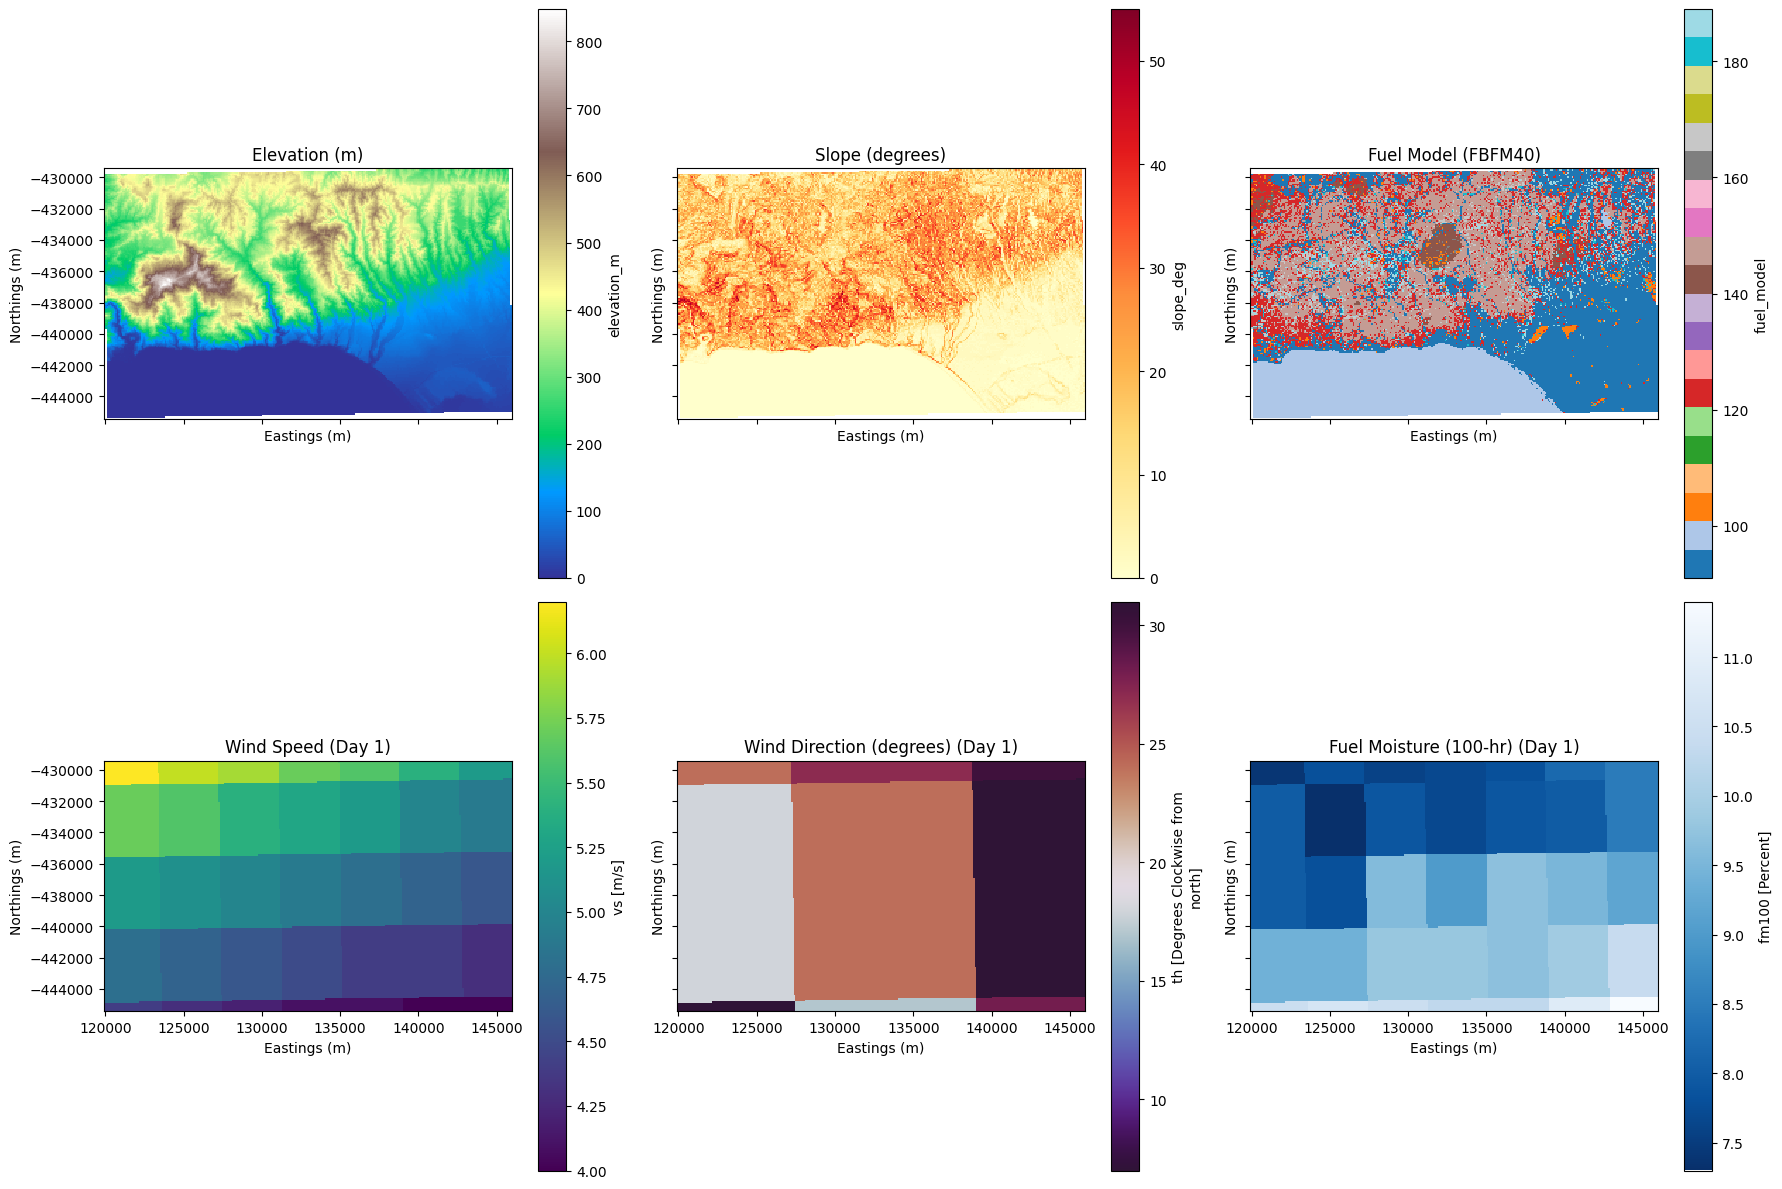

In [46]:
import matplotlib.pyplot as plt

# Load the stacked dataset for plotting
stacked_data = xr.open_dataset('palisades_stack.nc')

fig, axes = plt.subplots(ncols=3, nrows=2, figsize=(18, 12), sharex=True, sharey=True)
axes = axes.flatten()

# Define the variables to plot and their titles/colormaps
plot_vars = [
    ('elevation_m', 'Elevation (m)', 'terrain'),
    ('slope_deg', 'Slope (degrees)', 'YlOrRd'),
    ('fuel_model', 'Fuel Model (FBFM40)', 'tab20'), # Discrete colormap for fuel models
    ('wind_speed', 'Wind Speed', 'viridis'),
    ('wind_dir', 'Wind Direction (degrees)', 'twilight_shifted'),
    ('fuel_moisture', 'Fuel Moisture (100-hr)', 'Blues_r')
]

for i, (var_name, title, cmap) in enumerate(plot_vars):
    if var_name in stacked_data:
        ax = axes[i]
        # For time-varying data, plot the first timestep
        if 'day' in stacked_data[var_name].dims:
            data_to_plot = stacked_data[var_name].isel(day=0)
            title += ' (Day 1)'
        else:
            data_to_plot = stacked_data[var_name]

        data_to_plot.plot.imshow(ax=ax, cmap=cmap, add_colorbar=True)
        ax.set_title(title)
        ax.set_xlabel('Eastings (m)')
        ax.set_ylabel('Northings (m)')
        ax.set_aspect('equal', adjustable='box')
    else:
        axes[i].set_title(f'{var_name} not found')

plt.tight_layout()
plt.show()


In [33]:
# Install geemap, which includes earthengine-api as a dependency
!pip install geemap

In [34]:
import ee
import geemap

In [35]:
# Authenticate and initialize Earth Engine
try:
    # Replace 'your-gcp-project-id' with your actual Google Cloud Project ID.
    # You can find this in your Google Cloud Console or Earth Engine console.
    ee.Initialize(project='your-gcp-project-id')
    print('Earth Engine initialized successfully!')
except ee.EEException as e:
    print(f'Failed to initialize Earth Engine: {e}')
    print('Please ensure you have authenticated and provided a valid project ID in ee.Initialize().')

Failed to initialize Earth Engine: Project 'projects/your-gcp-project-id' not found or deleted.
Please ensure you have authenticated and provided a valid project ID in ee.Initialize().


In [36]:
# Run this cell to authenticate your Earth Engine account.
ee.Authenticate()

In [37]:
dataset = ee.ImageCollection('IDAHO_EPSCOR/GRIDMET').filter(
    ee.Filter.date('2018-08-01', '2018-08-15')
)

maximum_temperature = dataset.select('tmmx')

maximum_temperature_vis = {
    'min': 290.0,
    'max': 314.0,
    'palette': ['d8d8d8', '4addff', '5affa3', 'f2ff89', 'ff725c'],
}

m = geemap.Map()
m.set_center(-115.356, 38.686, 5)
m.add_layer(maximum_temperature, maximum_temperature_vis, 'Maximum Temperature')
m

EEException: Project 'projects/your-gcp-project-id' not found or deleted.